In [1]:
import numpy as np
import scanpy as sc
import pandas as pd
import numpy as np
from collections import Counter
from scipy import sparse
import anndata as ad
import pickle
import matplotlib.pyplot as plt
from torch import nn

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/anndata/utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/py

## RNA data

In [2]:
he_id = 'CTRL04_2010S1121_75_HE'
adata = sc.read_h5ad(f'../{he_id}_dbit_2026_genes_adata.h5ad')

In [3]:
adata

AnnData object with n_obs × n_vars = 2500 × 2026
    obs: 'array_col', 'array_row'

In [6]:
with open(f'../{he_id}_dbit_coords.pickle', 'rb') as handle:
    visium_coords = pickle.load(handle)

In [7]:
visium_coords.index = visium_coords.Barcode
visium_coords

,Barcode,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,lower_x,upper_x,lower_y,upper_y,lower_x_n1,...,lower_y_n6,upper_y_n6,lower_x_n7,upper_x_n7,lower_y_n7,upper_y_n7,lower_x_n8,upper_x_n8,lower_y_n8,upper_y_n8
Barcode,,,,,,,,,,,,,,,,,,,,,
1x1,1x1,1,1,25045.490518,11627.920653,11527.920653,11727.920653,24945.490518,25145.490518,11327.920653,...,24745.490518,24945.490518,11527.920653,11727.920653,24745.490518,24945.490518,11727.920653,11927.920653,24745.490518,24945.490518
1x3,1x3,3,1,25059.279182,12044.942747,11944.942747,12144.942747,24959.279182,25159.279182,11744.942747,...,24759.279182,24959.279182,11944.942747,12144.942747,24759.279182,24959.279182,12144.942747,12344.942747,24759.279182,24959.279182
1x5,1x5,5,1,25073.067846,12461.964842,12361.964842,12561.964842,24973.067846,25173.067846,12161.964842,...,24773.067846,24973.067846,12361.964842,12561.964842,24773.067846,24973.067846,12561.964842,12761.964842,24773.067846,24973.067846
1x7,1x7,7,1,25086.856511,12878.986937,12778.986937,12978.986937,24986.856511,25186.856511,12578.986937,...,24786.856511,24986.856511,12778.986937,12978.986937,24786.856511,24986.856511,12978.986937,13178.986937,24786.856511,24986.856511
1x9,1x9,9,1,25100.645175,13296.009032,13196.009032,13396.009032,25000.645175,25200.645175,12996.009032,...,24800.645175,25000.645175,13196.009032,13396.009032,24800.645175,25000.645175,13396.009032,13596.009032,24800.645175,25000.645175
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99x91,99x91,91,99,7434.686814,30385.651930,30285.651930,30485.651930,7334.686814,7534.686814,30085.651930,...,7134.686814,7334.686814,30285.651930,30485.651930,7134.686814,7334.686814,30485.651930,30685.651930,7134.686814,7334.686814
99x93,99x93,93,99,7448.475479,30802.674025,30702.674025,30902.674025,7348.475479,7548.475479,30502.674025,...,7148.475479,7348.475479,30702.674025,30902.674025,7148.475479,7348.475479,30902.674025,31102.674025,7148.475479,7348.475479
99x95,99x95,95,99,7462.264143,31219.696120,31119.696120,31319.696120,7362.264143,7562.264143,30919.696120,...,7162.264143,7362.264143,31119.696120,31319.696120,7162.264143,7362.264143,31319.696120,31519.696120,7162.264143,7362.264143


In [8]:
visium_coords_sub = visium_coords.loc[adata.obs_names, :].copy()
visium_coords_sub

,Barcode,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres,lower_x,upper_x,lower_y,upper_y,lower_x_n1,...,lower_y_n6,upper_y_n6,lower_x_n7,upper_x_n7,lower_y_n7,upper_y_n7,lower_x_n8,upper_x_n8,lower_y_n8,upper_y_n8
1x1,1x1,1,1,25045.490518,11627.920653,11527.920653,11727.920653,24945.490518,25145.490518,11327.920653,...,24745.490518,24945.490518,11527.920653,11727.920653,24745.490518,24945.490518,11727.920653,11927.920653,24745.490518,24945.490518
1x3,1x3,3,1,25059.279182,12044.942747,11944.942747,12144.942747,24959.279182,25159.279182,11744.942747,...,24759.279182,24959.279182,11944.942747,12144.942747,24759.279182,24959.279182,12144.942747,12344.942747,24759.279182,24959.279182
1x5,1x5,5,1,25073.067846,12461.964842,12361.964842,12561.964842,24973.067846,25173.067846,12161.964842,...,24773.067846,24973.067846,12361.964842,12561.964842,24773.067846,24973.067846,12561.964842,12761.964842,24773.067846,24973.067846
1x7,1x7,7,1,25086.856511,12878.986937,12778.986937,12978.986937,24986.856511,25186.856511,12578.986937,...,24786.856511,24986.856511,12778.986937,12978.986937,24786.856511,24986.856511,12978.986937,13178.986937,24786.856511,24986.856511
1x9,1x9,9,1,25100.645175,13296.009032,13196.009032,13396.009032,25000.645175,25200.645175,12996.009032,...,24800.645175,25000.645175,13196.009032,13396.009032,24800.645175,25000.645175,13396.009032,13596.009032,24800.645175,25000.645175
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99x91,99x91,91,99,7434.686814,30385.651930,30285.651930,30485.651930,7334.686814,7534.686814,30085.651930,...,7134.686814,7334.686814,30285.651930,30485.651930,7134.686814,7334.686814,30485.651930,30685.651930,7134.686814,7334.686814
99x93,99x93,93,99,7448.475479,30802.674025,30702.674025,30902.674025,7348.475479,7548.475479,30502.674025,...,7148.475479,7348.475479,30702.674025,30902.674025,7148.475479,7348.475479,30902.674025,31102.674025,7148.475479,7348.475479
99x95,99x95,95,99,7462.264143,31219.696120,31119.696120,31319.696120,7362.264143,7562.264143,30919.696120,...,7162.264143,7362.264143,31119.696120,31319.696120,7162.264143,7362.264143,31319.696120,31519.696120,7162.264143,7362.264143
99x97,99x97,97,99,7476.052808,31636.718215,31536.718215,31736.718215,7376.052808,7576.052808,31336.718215,...,7176.052808,7376.052808,31536.718215,31736.718215,7176.052808,7376.052808,31736.718215,31936.718215,7176.052808,7376.052808


In [9]:
adata.obs['array_row'] = np.array(visium_coords_sub.array_row)
adata.obs['array_col'] = np.array(visium_coords_sub.array_col)
adata.obs['x'] = np.array(visium_coords_sub.pxl_col_in_fullres)
adata.obs['y'] = np.array(visium_coords_sub.pxl_row_in_fullres)
adata.obsm['spatial'] = np.array([np.array(visium_coords_sub.pxl_col_in_fullres), np.array(visium_coords_sub.pxl_row_in_fullres)]).T
adata.layers['counts'] = adata.X.copy()

In [10]:
gene_list = list(adata.var_names)

In [13]:
import sys
import os

# Get the absolute path to the directory containing the script to be imported
script_dir = os.path.abspath("../SuperFocus")

# Add the directory to sys.path
sys.path.append(script_dir)

In [26]:
from importlib import reload
import src.model_training.model_training_orig
import src.model_training.processing_image_features
reload(src.model_training.model_training_orig)
reload(src.model_training.processing_image_features)
from src.model_training.model_training_orig import training_orig

In [30]:
sample_id = 'CTRL04_2010S1121_75_HE'
he_id = '2010S1121_75_HE'

In [31]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training_orig(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, feature_list=gene_list, 
              save_model_dir=f'./logs_{sample_id}_reproduce', hidden_dims=[8192, 4096, 4096, 8192], activations=None, residual=False, norm=False, out_act=None, 
              include_tanhshrink=False, sample_id=sample_id, training_mode='Full_3', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id}_cellvit_embed_rotated.pickle', sort_way='col_row', datatype='dbit')

/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/scanpy/preprocessing/_qc.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[obs_metrics.columns] = obs_metrics


(2075, 3609)


Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/catalyst/core/misc.py:119: UserWarning: No ``ICriterionCallback/CriterionCallback`` were found while runner.criterion is not None.Do you compute the loss during ``runner.handle_batch``?
  warnings.warn(
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/catalyst/core/misc.py:127: UserWarning: No ``IBackwardCallback/BackwardCallback`` were found while runner.criterion/optimizer is not None.Do you backward the loss during ``runner.handle_batch``?
  warnings.warn(
/gpfs/gibbs/project/fan/yl2499/conda_envs/iStar/lib/python3.11/site-packages/catalyst/core/misc.py:133: UserWarning: No ``IOptimizerCallback/OptimizerCallback`` were found while runner.optimizer is not None.Do run optimisation step pass dur

train (1/50) loss: 0.26953081731738776
valid (1/50) loss: 0.31102864213168296
* Epoch (1/50) 
train (2/50) loss: 0.2585083174669575
valid (2/50) loss: 0.3086394629376457
* Epoch (2/50) 
train (3/50) loss: 0.2580619304997962
valid (3/50) loss: 0.3084039815606918
* Epoch (3/50) 
train (4/50) loss: 0.2577737208907427
valid (4/50) loss: 0.3080425616254144
* Epoch (4/50) 
train (5/50) loss: 0.25742593772923955
valid (5/50) loss: 0.30748978974347446
* Epoch (5/50) 
train (6/50) loss: 0.2563517292872899
valid (6/50) loss: 0.30688782044273005
* Epoch (6/50) 
train (7/50) loss: 0.2553934266881821
valid (7/50) loss: 0.3018903550617198
* Epoch (7/50) 
train (8/50) loss: 0.2508508258630825
valid (8/50) loss: 0.29692067787609
* Epoch (8/50) 
train (9/50) loss: 0.242481689523389
valid (9/50) loss: 0.2836362480479766
* Epoch (9/50) 
train (10/50) loss: 0.2353029456401302
valid (10/50) loss: 0.30534227678482545
* Epoch (10/50) 
train (11/50) loss: 0.2354247488695267
valid (11/50) loss: 0.2966445403940

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


* Epoch (50/50) 
Top models:
./logs_CTRL04_2010S1121_75_HE_reproduce/checkpoints/model.0016.pth	0.2774
train (1/50) loss: 0.21588546507764167
valid (1/50) loss: 0.18517846418893275
* Epoch (1/50) 
train (2/50) loss: 0.20225170642955942
valid (2/50) loss: 0.15011138807643543
* Epoch (2/50) 
train (3/50) loss: 0.20174974614313917
valid (3/50) loss: 0.1511267120426989
* Epoch (3/50) 
train (4/50) loss: 0.1858395374837292
valid (4/50) loss: 0.15651613298584435
* Epoch (4/50) 
train (5/50) loss: 0.1878280004278095
valid (5/50) loss: 0.16426865537376964
* Epoch (5/50) 
train (6/50) loss: 0.18867870103330797
valid (6/50) loss: 0.1496465353564145
* Epoch (6/50) 
train (7/50) loss: 0.17798268670753908
valid (7/50) loss: 0.18811232158366373
* Epoch (7/50) 
train (8/50) loss: 0.20091443558267835
valid (8/50) loss: 0.16511068186339206
* Epoch (8/50) 
train (9/50) loss: 0.17848974342812893
valid (9/50) loss: 0.15768723906998966
* Epoch (9/50) 
train (10/50) loss: 0.18640513174679962
valid (10/50) l

... (2 outputs left out)

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


* Epoch (50/50) 
Top models:
./logs_CTRL04_2010S1121_75_HE_reproduce/checkpoints/model.0003.pth	0.1020
train (1/50) loss: 0.1257160922270542
valid (1/50) loss: 0.16314300575141294
* Epoch (1/50) 
train (2/50) loss: 0.12442987159871989
valid (2/50) loss: 0.1618451675045586
* Epoch (2/50) 
train (3/50) loss: 0.13235422156980559
valid (3/50) loss: 0.2106003075358695
* Epoch (3/50) 
train (4/50) loss: 0.140493590978175
valid (4/50) loss: 0.168823859207432
* Epoch (4/50) 
train (5/50) loss: 0.12341983125631113
valid (5/50) loss: 0.16268134512626453
* Epoch (5/50) 
train (6/50) loss: 0.12128649131859962
valid (6/50) loss: 0.16302683406157403
* Epoch (6/50) 
train (7/50) loss: 0.11961330267958532
valid (7/50) loss: 0.16241948570227174
* Epoch (7/50) 
train (8/50) loss: 0.11916283558969355
valid (8/50) loss: 0.16424218583202874
* Epoch (8/50) 
train (9/50) loss: 0.11860361610011881
valid (9/50) loss: 0.1642641578938303
* Epoch (9/50) 
train (10/50) loss: 0.11804443348443494
valid (10/50) loss:

Detected kernel version 4.18.0, which is below the recommended minimum of 5.5.0; this can cause the process to hang. It is recommended to upgrade the kernel to the minimum version or higher.


* Epoch (50/50) 
Top models:
./logs_CTRL04_2010S1121_75_HE_reproduce/checkpoints/model.0002.pth	0.1618
train (1/50) loss: 0.1377706390467673
valid (1/50) loss: 0.12320726890186842
* Epoch (1/50) 
train (2/50) loss: 0.1278105367379016
valid (2/50) loss: 0.11524732103296642
* Epoch (2/50) 
train (3/50) loss: 0.1244969053600367
valid (3/50) loss: 0.12110495371569256
* Epoch (3/50) 
train (4/50) loss: 0.12583437277729734
valid (4/50) loss: 0.11841165358275574
* Epoch (4/50) 
train (5/50) loss: 0.12267506414827412
valid (5/50) loss: 0.12232499030336301
* Epoch (5/50) 
train (6/50) loss: 0.12231118881319421
valid (6/50) loss: 0.11975079862745454
* Epoch (6/50) 
train (7/50) loss: 0.11964021858521096
valid (7/50) loss: 0.11908742853367936
* Epoch (7/50) 
train (8/50) loss: 0.12058519108727114
valid (8/50) loss: 0.1267457853892853
* Epoch (8/50) 
train (9/50) loss: 0.11899719057153349
valid (9/50) loss: 0.1203175602785384
* Epoch (9/50) 
train (10/50) loss: 0.11832708577155428
valid (10/50) lo

In [33]:
import src.post_process
from importlib import reload
reload(src.post_process)
from src.post_process import post_training_processing

In [34]:
adata_pred = post_training_processing.post_procesing(model_dir=f'./logs_{sample_id}_reproduce/checkpoints/model.best.pth', hidden_dims=[8192, 4096, 4096, 8192], 
                                               activations=None, out_act=None, residual=False, norm=False, selected_model='lite_shrink', include_tanhshrink=False, 
                                               data_dir=f'./{sample_id}_training_data_level1.pickle', feature_list=gene_list, datatype='RNA', regress_out=False, resolutions=[0.6, 0.8],
                                               refine_factor=1, sample_id=sample_id, radius=200./2)

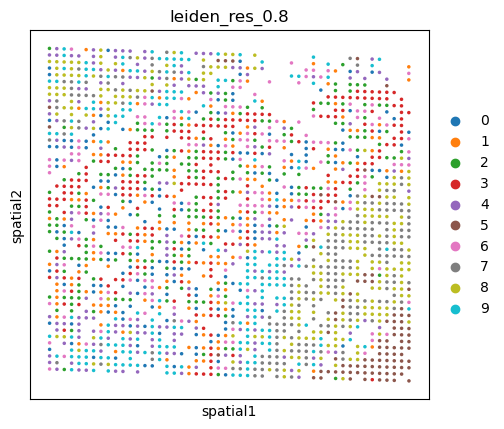

In [35]:
sc.pl.spatial(adata_pred, img_key=None, color='leiden_res_0.8')

In [28]:
import src.model_training.model_training_refined
reload(src.model_training.model_training_refined)
from src.model_training.model_training_refined import training

In [61]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, refine_factor=2, 
         feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce/checkpoints/model.best.pth',
         save_model_dir=f'./logs_{sample_id}_reproduce_2x', hidden_dims=[8192, 4096, 4096, 8192], activations=None, residual=False, norm=False, out_act=None, 
         include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id}_cellvit_embed_rotated.pickle', 
         lr=1e-7, step_size=25, gamma=0.5, num_epochs=50, sort_way='col_row', random_state=42, datatype='dbit')

number of selected original spots in training:  1867
number of selected refined spots in training:  3833

 Fold 1


/gpfs/gibbs/project/fan/yl2499/code/SuperFocus/src/model_training/model_training_refined.py:89: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  gene_counts = preds * torch.tensor(num_cells).unsqueeze(1)


Epoch 1: Validation Loss = 292.4490
Saved best model for fold 1 at epoch 1
Epoch 2: Validation Loss = 291.9482
Saved best model for fold 1 at epoch 2
Epoch 3: Validation Loss = 291.1382
Saved best model for fold 1 at epoch 3
Epoch 4: Validation Loss = 290.5526
Saved best model for fold 1 at epoch 4
Epoch 5: Validation Loss = 290.1429
Saved best model for fold 1 at epoch 5
Epoch 6: Validation Loss = 289.8414
Saved best model for fold 1 at epoch 6
Epoch 7: Validation Loss = 289.6108
Saved best model for fold 1 at epoch 7
Epoch 8: Validation Loss = 289.4431
Saved best model for fold 1 at epoch 8
Epoch 9: Validation Loss = 289.2898
Saved best model for fold 1 at epoch 9
Epoch 10: Validation Loss = 289.1626
Saved best model for fold 1 at epoch 10
Epoch 11: Validation Loss = 289.0239
Saved best model for fold 1 at epoch 11
Epoch 12: Validation Loss = 288.9048
Saved best model for fold 1 at epoch 12
Epoch 13: Validation Loss = 288.7888
Saved best model for fold 1 at epoch 13
Epoch 14: Validat

In [ ]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, refine_factor=4, 
         feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce_2x/best_model_fold2.pth',
         save_model_dir=f'./logs_{sample_id}_reproduce_4x', hidden_dims=[8192, 4096, 4096, 8192], activations=None, residual=False, norm=False, out_act=None, 
         include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id}_cellvit_embed_rotated.pickle', 
         lr=1e-8, step_size=25, gamma=0.5, num_epochs=50, sort_way='col_row', random_state=42, datatype='dbit')

## ATAC-seq data

In [21]:
sample_id0 = 'CTRL04_2010S1121_75_HE'
he_id = '2010S1121_75_HE'

### ATAC-seq part 1

In [23]:
sample_id = 'CTRL04_2010S1121_75_HE_atac1'
adata = sc.read_h5ad(f'../{sample_id}_5_percent_adata.h5ad')

In [ ]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training_orig(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, feature_list=list(adata.var_names), 
              save_model_dir=f'./logs_{sample_id}_reproduce', hidden_dims=[8192, 4096, 4096, 8132], activations=None, residual=False, norm=False, out_act=None, 
              include_tanhshrink=True, sample_id=sample_id, training_mode='Full_3', selected_model='lite_shrink', lr=1e-6,  kfold=5, cell_embed_dir=f'../{sample_id0}_cellvit_embed_rotated.pickle', sort_way='col_row', datatype='dbit')

In [ ]:
set_global_seed(123)
training(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, refine_factor=2, 
         feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce/checkpoints/model.best.pth',
         save_model_dir=f'./logs_{sample_id}_reproduce_2x', hidden_dims=[8192, 4096, 4096, 8132], activations=None, residual=False, norm=False, out_act=None, 
         include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id0}_cellvit_embed_rotated.pickle', 
         lr=1e-7, step_size=25, gamma=0.5, num_epochs=50, sort_way='col_row', random_state=42, datatype='dbit', max_fold=1)

In [ ]:
training(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, refine_factor=4, 
         feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce_2x/best_model_fold1.pth',
         save_model_dir=f'./logs_{sample_id}_reproduce_4x', hidden_dims=[8192, 4096, 4096, 8132], activations=None, residual=False, norm=False, out_act=None, 
         include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id0}_cellvit_embed_rotated.pickle', 
         lr=1e-7, step_size=25, gamma=0.5, num_epochs=50, sort_way='col_row', random_state=42, datatype='dbit', max_fold=1)

### ATAC-seq part 2

In [29]:
sample_id = 'CTRL04_2010S1121_75_HE_atac2'
adata = sc.read_h5ad(f'../{sample_id}_4-5_percent_adata.h5ad')

In [ ]:
from catalyst.utils import set_global_seed
set_global_seed(123)
training_orig(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, feature_list=list(adata.var_names), 
              save_model_dir=f'./logs_{sample_id}_reproduce', hidden_dims=[8192, 4096, 4096, 8132], activations=None, residual=False, norm=False, out_act=None, 
              include_tanhshrink=True, sample_id=sample_id, training_mode='Full_3', selected_model='lite_shrink', lr=1e-6,  kfold=5, cell_embed_dir=f'../{sample_id0}_cellvit_embed_rotated.pickle', sort_way='col_row', datatype='dbit')

In [ ]:
set_global_seed(123)
training(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, refine_factor=2, 
         feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce/checkpoints/model.best.pth',
         save_model_dir=f'./logs_{sample_id}_reproduce_2x', hidden_dims=[8192, 4096, 4096, 8132], activations=None, residual=False, norm=False, out_act=None, 
         include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id0}_cellvit_embed_rotated.pickle', 
         lr=1e-7, step_size=25, gamma=0.5, num_epochs=50, sort_way='col_row', random_state=42, datatype='dbit', max_fold=1)

In [ ]:
training(adata=adata, pt_model_dir=f'../CellViT/Brain/preprocessing/{he_id}/{he_id}/cell_detection', radius=200./2, refine_factor=4, 
         feature_pd_dir=f'./{sample_id}_gene_exp_pd.pickle', 
         trained_model_dir=f'./logs_{sample_id}_reproduce_2x/best_model_fold1.pth',
         save_model_dir=f'./logs_{sample_id}_reproduce_4x', hidden_dims=[8192, 4096, 4096, 8132], activations=None, residual=False, norm=False, out_act=None, 
         include_tanhshrink=False, sample_id=sample_id, training_mode='Full_2', selected_model='lite_shrink', kfold=5, cell_embed_dir=f'./{sample_id0}_cellvit_embed_rotated.pickle', 
         lr=1e-7, step_size=25, gamma=0.5, num_epochs=50, sort_way='col_row', random_state=42, datatype='dbit', max_fold=1)